# 02 - Exploratory Data Analysis & Subword Tokenization Fragmentation
**Project:** Robustness of Roman Urdu Sentiment Classification to Orthographic Spelling Variation  
**Course:** Data Science Tools & Techniques (DS T&T)  
**Author:** Danyal Ahmed Malik (26i-8030)

---
### Pipeline Overview & Objectives
1. **Corpus Morphological & Statistical Profiling:** Analyze review length distributions, vocabulary coverage, and type-token ratios across sentiment classes.
2. **Lexicon Character-Level Analysis:** Compute Levenshtein edit distance distributions across 10,869 authentic variant pairs.
3. **Subword Fragmentation & Fertility Analysis:** Quantify tokenization behavior across WordPiece (`bert-base-multilingual-cased`) and SentencePiece/BPE (`xlm-roberta-base`).
4. **Visual Synthesis:** Inspect review lengths, lexicon variant counts, edit distance spreads, and tokenizer fragmentation charts.


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)


### 1. Summary Statistics & Review Lengths
Load and display the computed summary statistics for the cleaned corpus.


In [2]:
stats_path = os.path.join(PROJECT_ROOT, "results", "tables", "eda_summary_statistics.json")
with open(stats_path, "r", encoding="utf-8") as f:
    eda_stats = json.load(f)

print(json.dumps(eda_stats, indent=2))

len_path = os.path.join(PROJECT_ROOT, "results", "tables", "review_length_by_sentiment.csv")
len_df = pd.read_csv(len_path)
display(len_df)


{
  "total_cleaned_reviews": 23458,
  "mean_word_count": 14.164592036831785,
  "median_word_count": 10.0,
  "p95_word_count": 40.0,
  "mean_ttr": 0.9480872118596984,
  "lexicon_headwords": 5219,
  "lexicon_total_unique_words": 16077,
  "reviews_with_lexicon_match_pct": 96.2997698013471,
  "overall_lexicon_density_mean": 0.5585940062367145,
  "distance_stats": {
    "total_pairs": 10869,
    "levenshtein_mean": 1.4719845431962462,
    "levenshtein_std": 0.708583429118722,
    "levenshtein_median": 1.0,
    "levenshtein_min": 1,
    "levenshtein_max": 9,
    "norm_levenshtein_mean": 0.23161236898471235,
    "norm_levenshtein_std": 0.10818349133536516,
    "norm_levenshtein_median": 0.2,
    "distance_frequencies": {
      "1": 6864,
      "2": 3082,
      "3": 754,
      "4": 143,
      "5": 23,
      "6": 1,
      "7": 1,
      "9": 1
    }
  }
}


,sentiment,Mean,Std,Median,Q25,Q75,Q95,Max
0,very negative,11.10,13.00,7.0,4.0,13.0,34.0,200
1,negative,15.72,16.41,11.0,7.0,18.0,44.0,320
2,neutral,13.98,16.05,9.0,6.0,16.0,39.0,357
3,positive,16.52,17.34,12.0,7.0,21.0,44.0,362
4,very positive,9.78,9.79,7.0,4.0,11.0,26.0,183


### 2. Review Length Distribution & Sentiment Class Spread


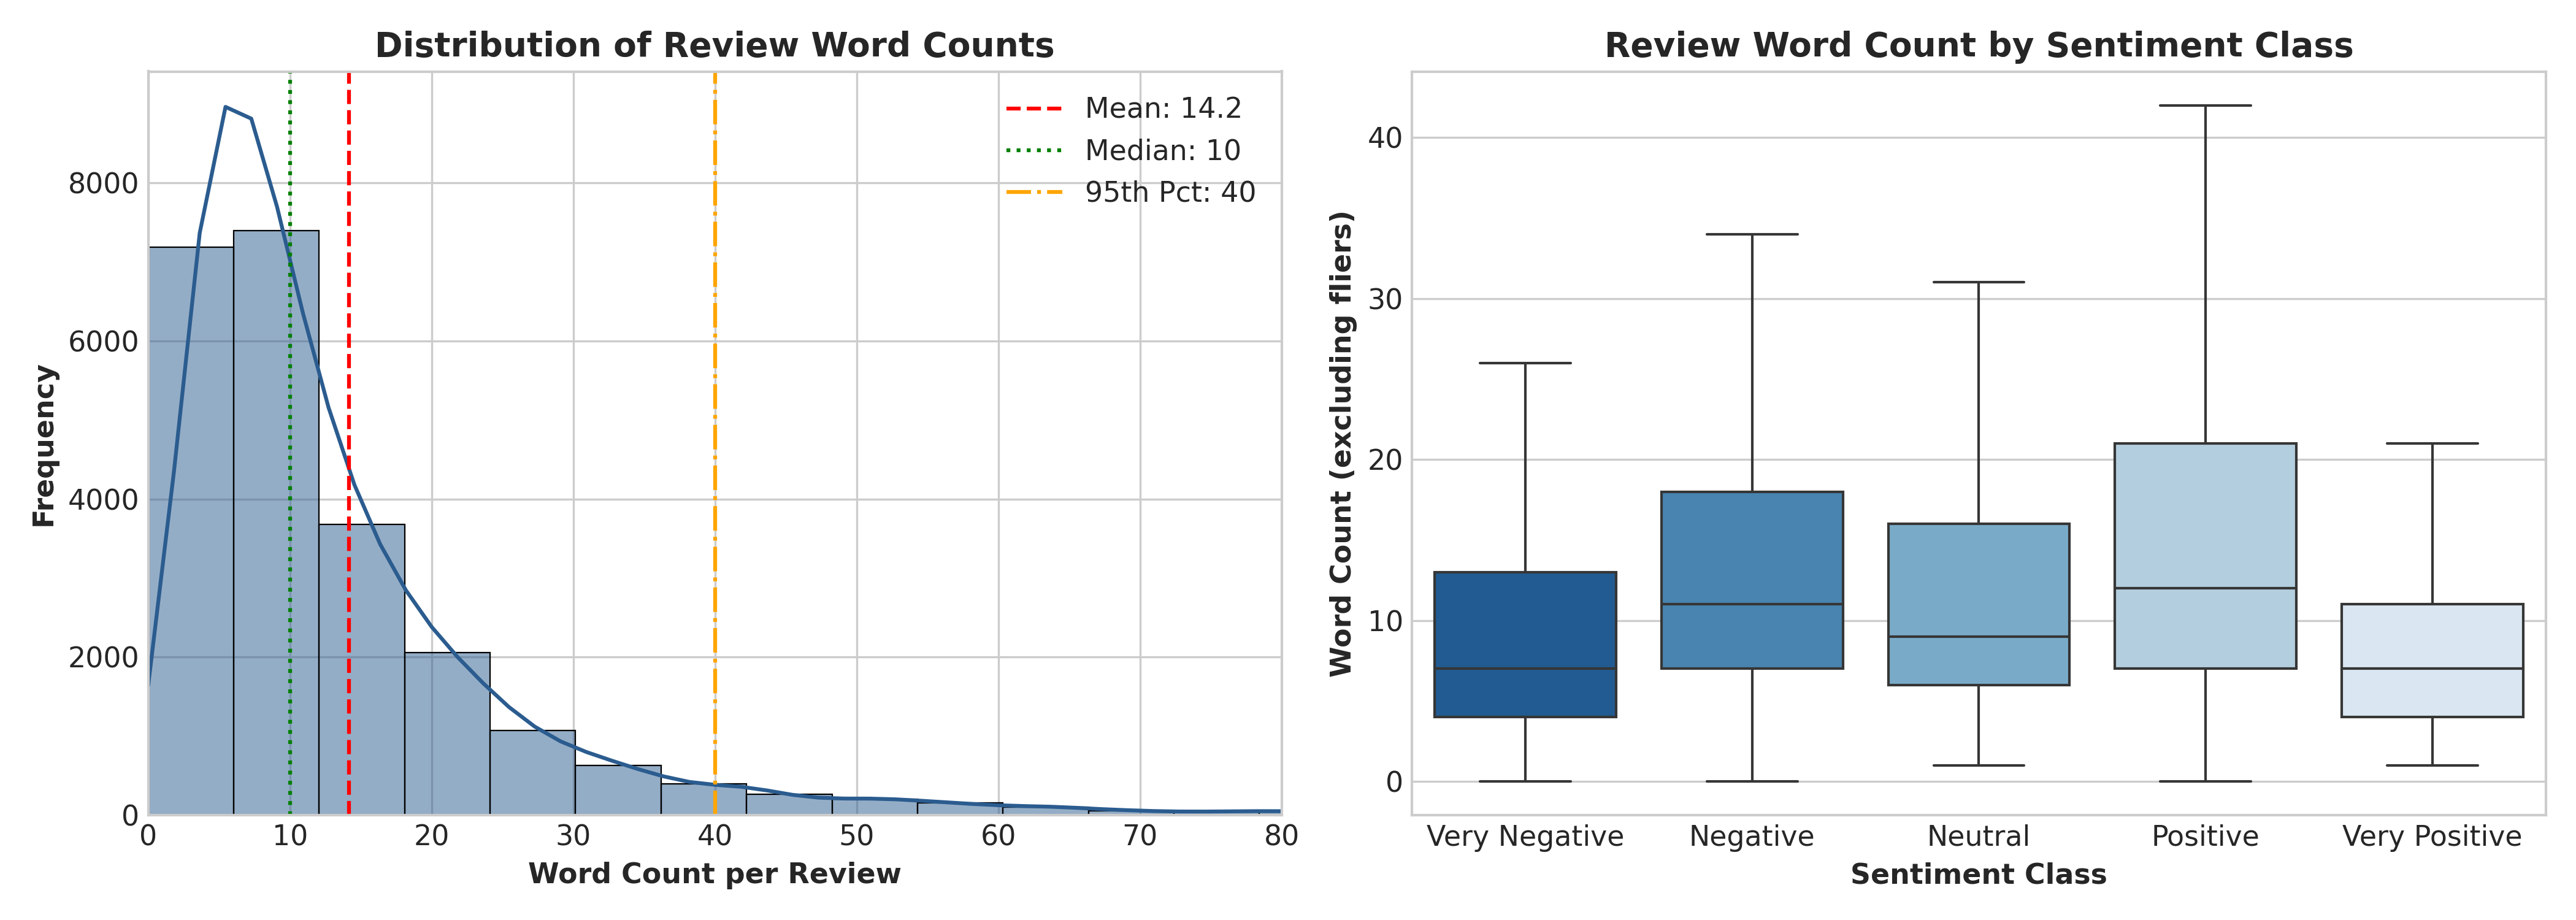

In [3]:
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "review_length_distribution.png")))


### 3. Lexical Variant Analysis & Edit Distance Metrics
Inspect spelling variation depth, variant density per class, and Levenshtein edit distance distribution.


In [4]:
dist_stats_path = os.path.join(PROJECT_ROOT, "results", "tables", "lexicon_distance_stats.json")
with open(dist_stats_path, "r", encoding="utf-8") as f:
    dist_stats = json.load(f)

print("Levenshtein Distance Statistics:")
print(json.dumps(dist_stats, indent=2))

cov_path = os.path.join(PROJECT_ROOT, "results", "tables", "lexicon_coverage_by_sentiment.csv")
cov_df = pd.read_csv(cov_path)
display(cov_df)


Levenshtein Distance Statistics:
{
  "total_pairs": 10869,
  "levenshtein_mean": 1.4719845431962462,
  "levenshtein_std": 0.708583429118722,
  "levenshtein_median": 1.0,
  "levenshtein_min": 1,
  "levenshtein_max": 9,
  "norm_levenshtein_mean": 0.23161236898471235,
  "norm_levenshtein_std": 0.10818349133536516,
  "norm_levenshtein_median": 0.2,
  "distance_frequencies": {
    "1": 6864,
    "2": 3082,
    "3": 754,
    "4": 143,
    "5": 23,
    "6": 1,
    "7": 1,
    "9": 1
  }
}


,sentiment,Total_Reviews,Reviews_With_Match,Coverage_Pct,Mean_Matches,Median_Matches,Mean_Density,Median_Density
0,very negative,2585,2457,95.048,6.785,4.0,0.586,0.607
1,negative,5731,5618,98.028,9.702,7.0,0.597,0.615
2,neutral,6066,5832,96.142,7.754,5.0,0.534,0.556
3,positive,5917,5732,96.873,9.718,7.0,0.562,0.583
4,very positive,3159,2951,93.416,5.277,4.0,0.506,0.500


### 4. Variant Count & Edit Distance Visualizations


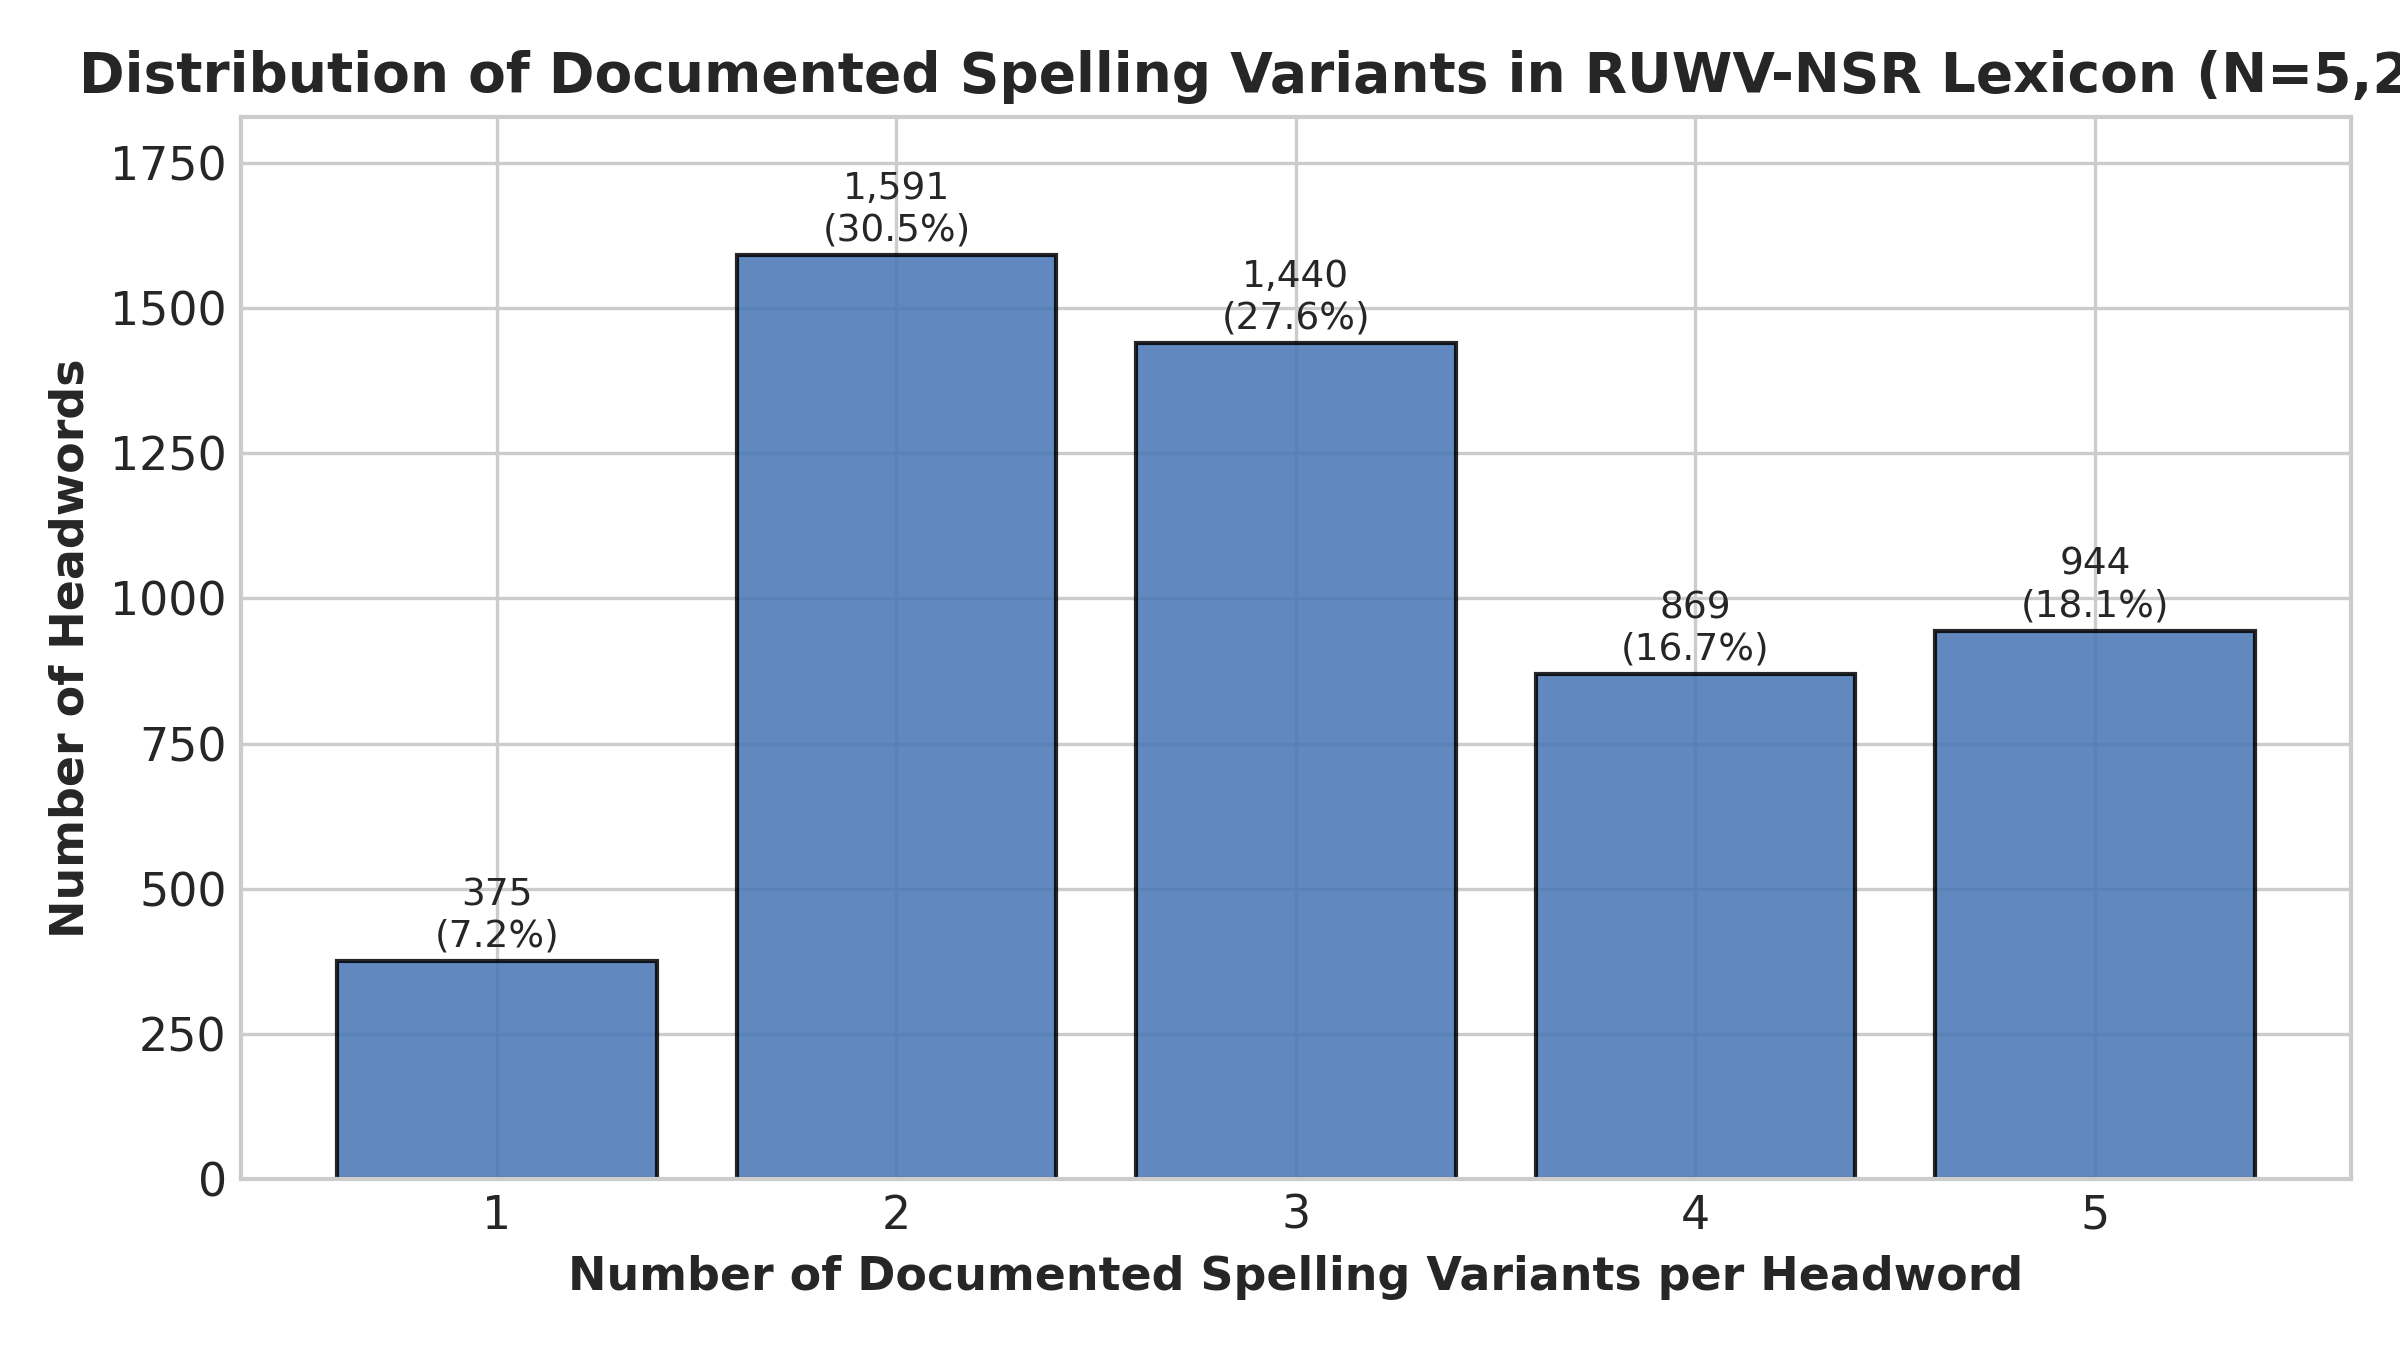

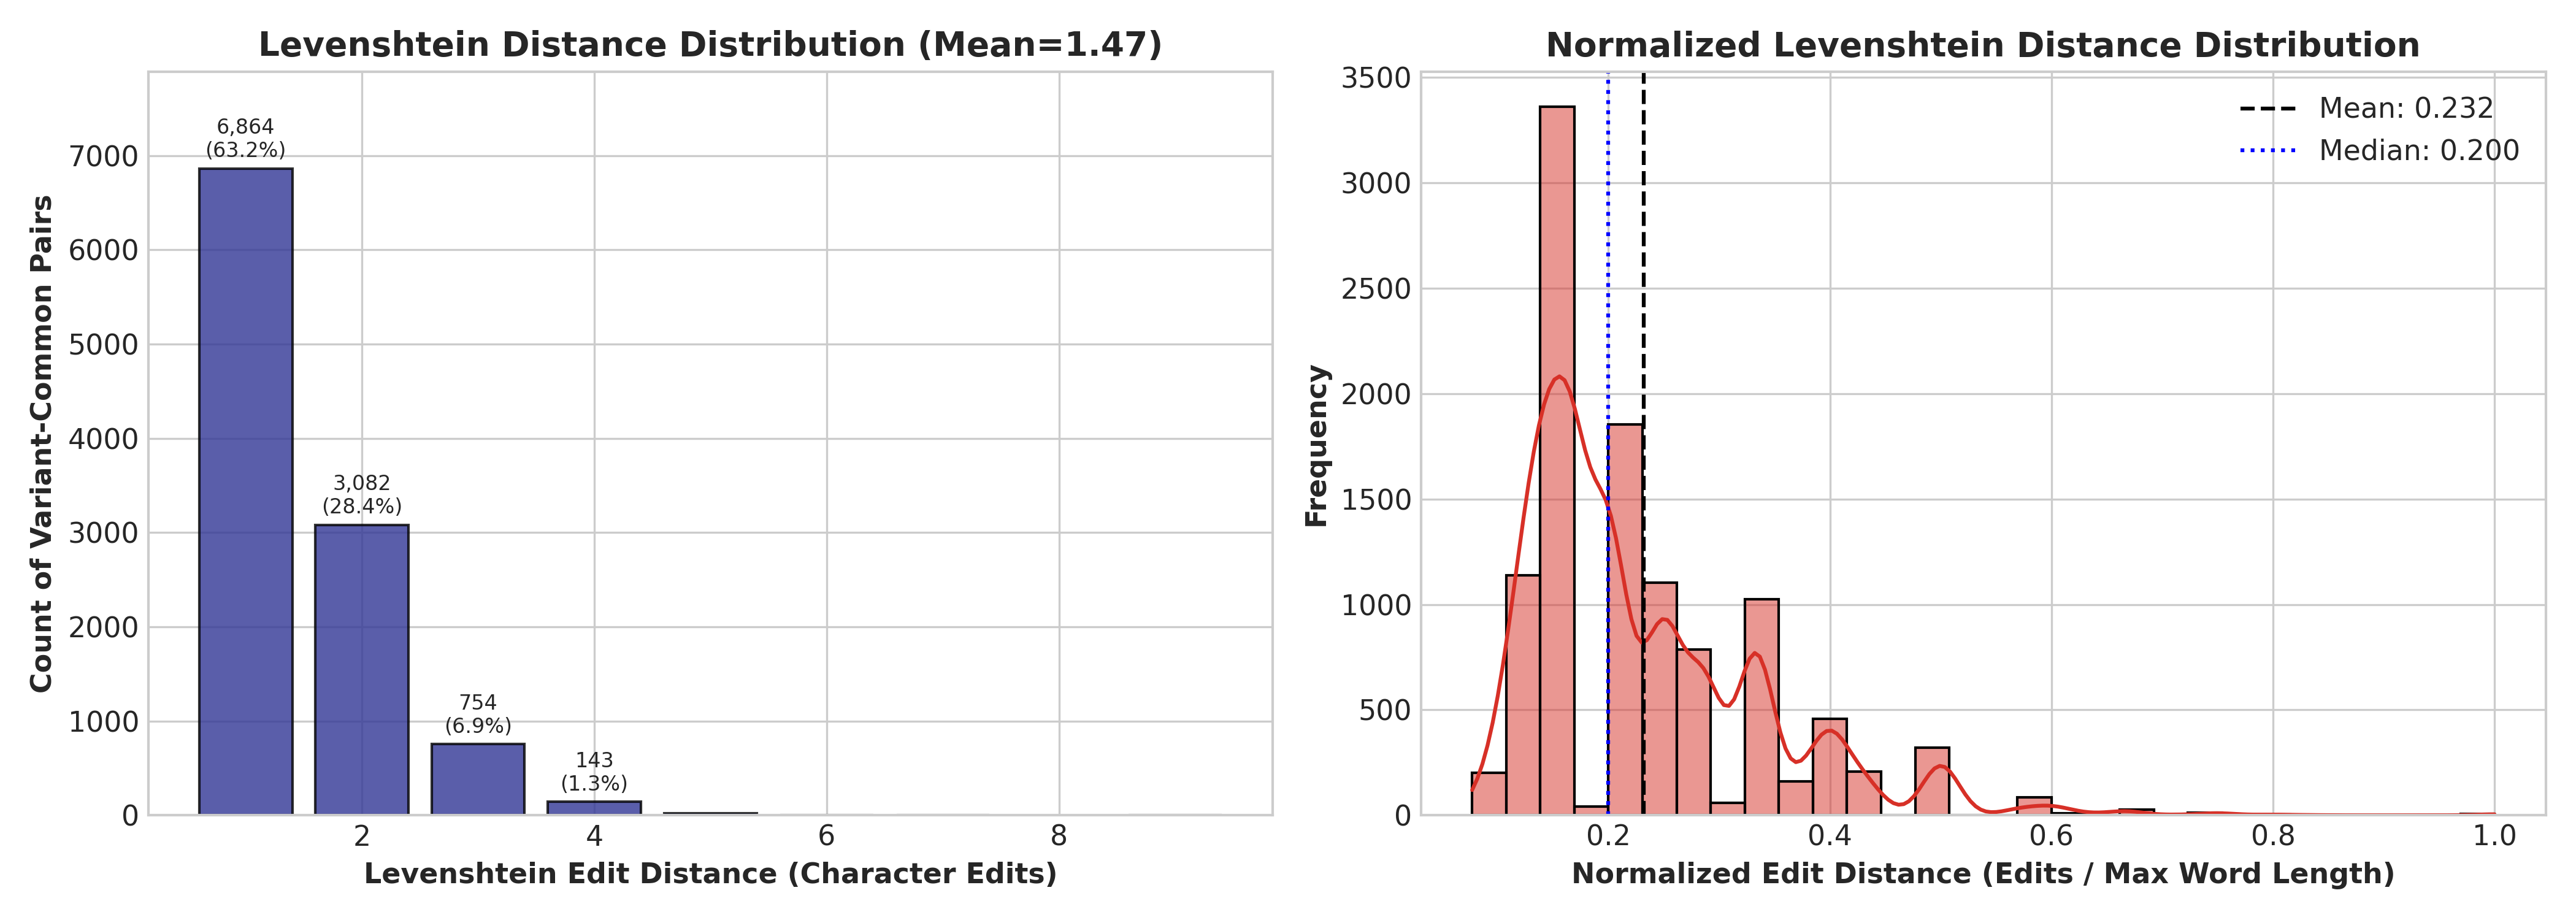

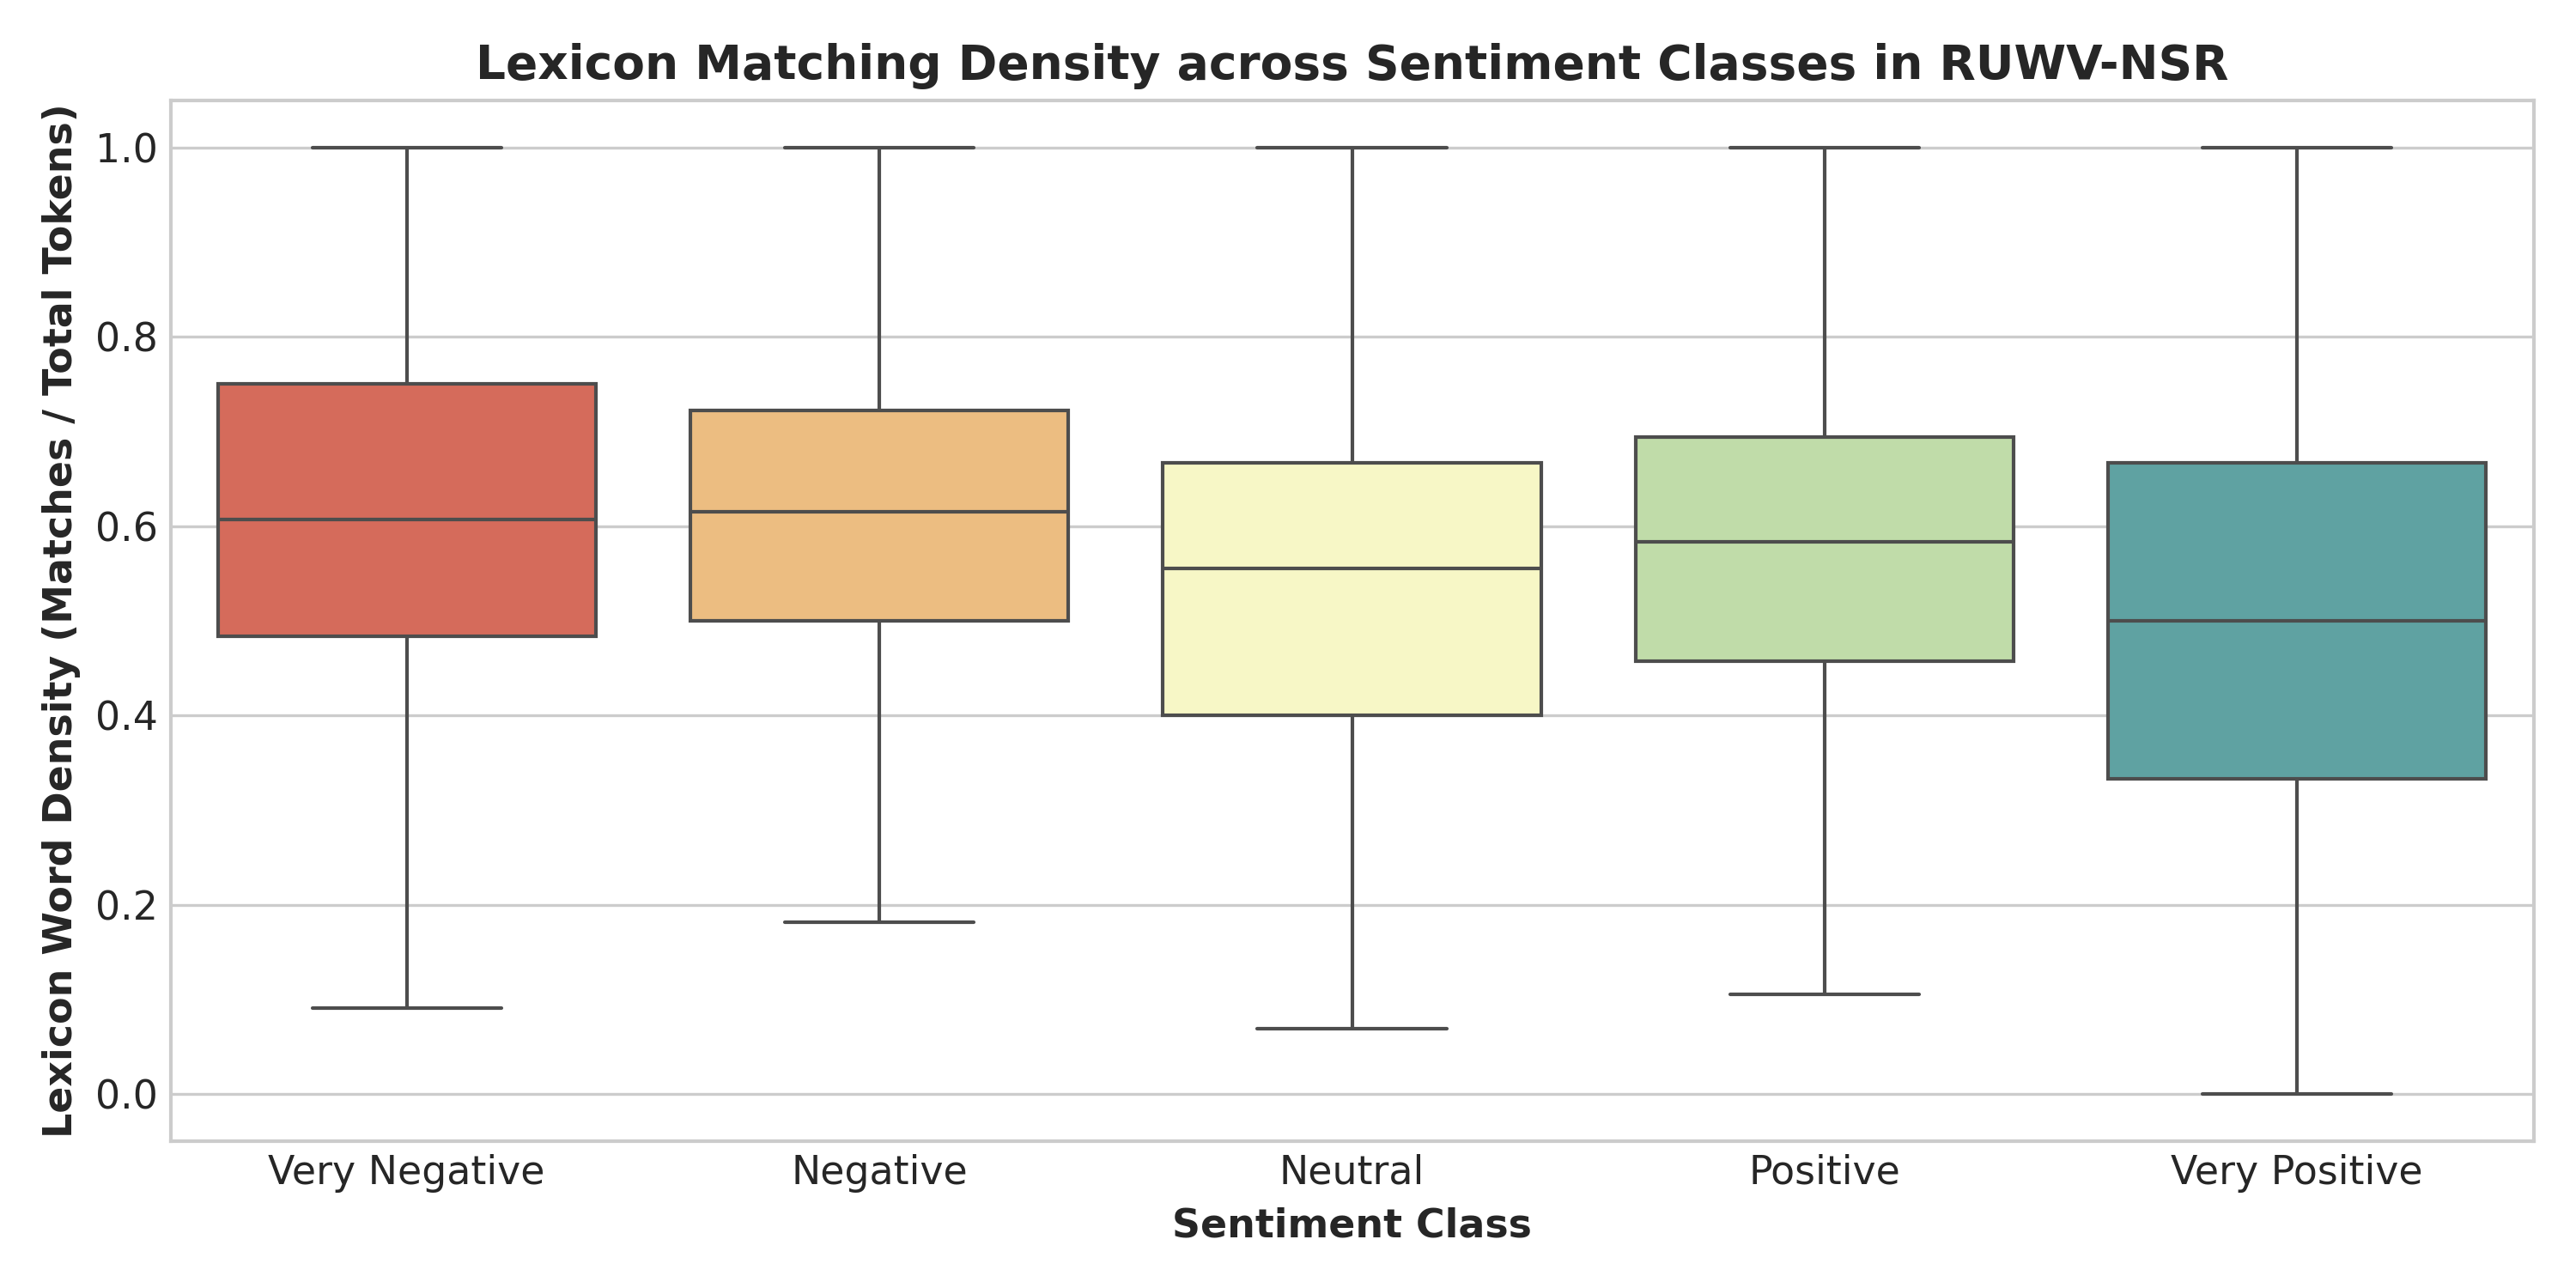

In [5]:
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "lexicon_variant_counts.png")))
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "variant_edit_distances.png")))
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "lexicon_density_per_class.png")))


### 5. Subword Fragmentation Analysis (mBERT vs XLM-RoBERTa)
Compare how WordPiece and SentencePiece tokenize Roman Urdu canonical headwords versus their noisy authentic spelling variants.


Tokenizer Fragmentation Summary:
{
  "total_pairs_analyzed": 10869,
  "mbert": {
    "mean_common_subwords": 2.4721685527647437,
    "mean_variant_subwords": 2.595270954089613,
    "pct_fragmentation_increase": 24.252461127978655,
    "pct_unchanged": 63.170484865213,
    "pct_decreased": 12.577054006808355,
    "mean_increase": 0.1231024013248689
  },
  "xlmr": {
    "mean_common_subwords": 2.2767503910203333,
    "mean_variant_subwords": 2.448155304075812,
    "pct_fragmentation_increase": 27.45422761983623,
    "pct_unchanged": 60.87956573741835,
    "pct_decreased": 11.666206642745424,
    "mean_increase": 0.1714049130554789
  }
}


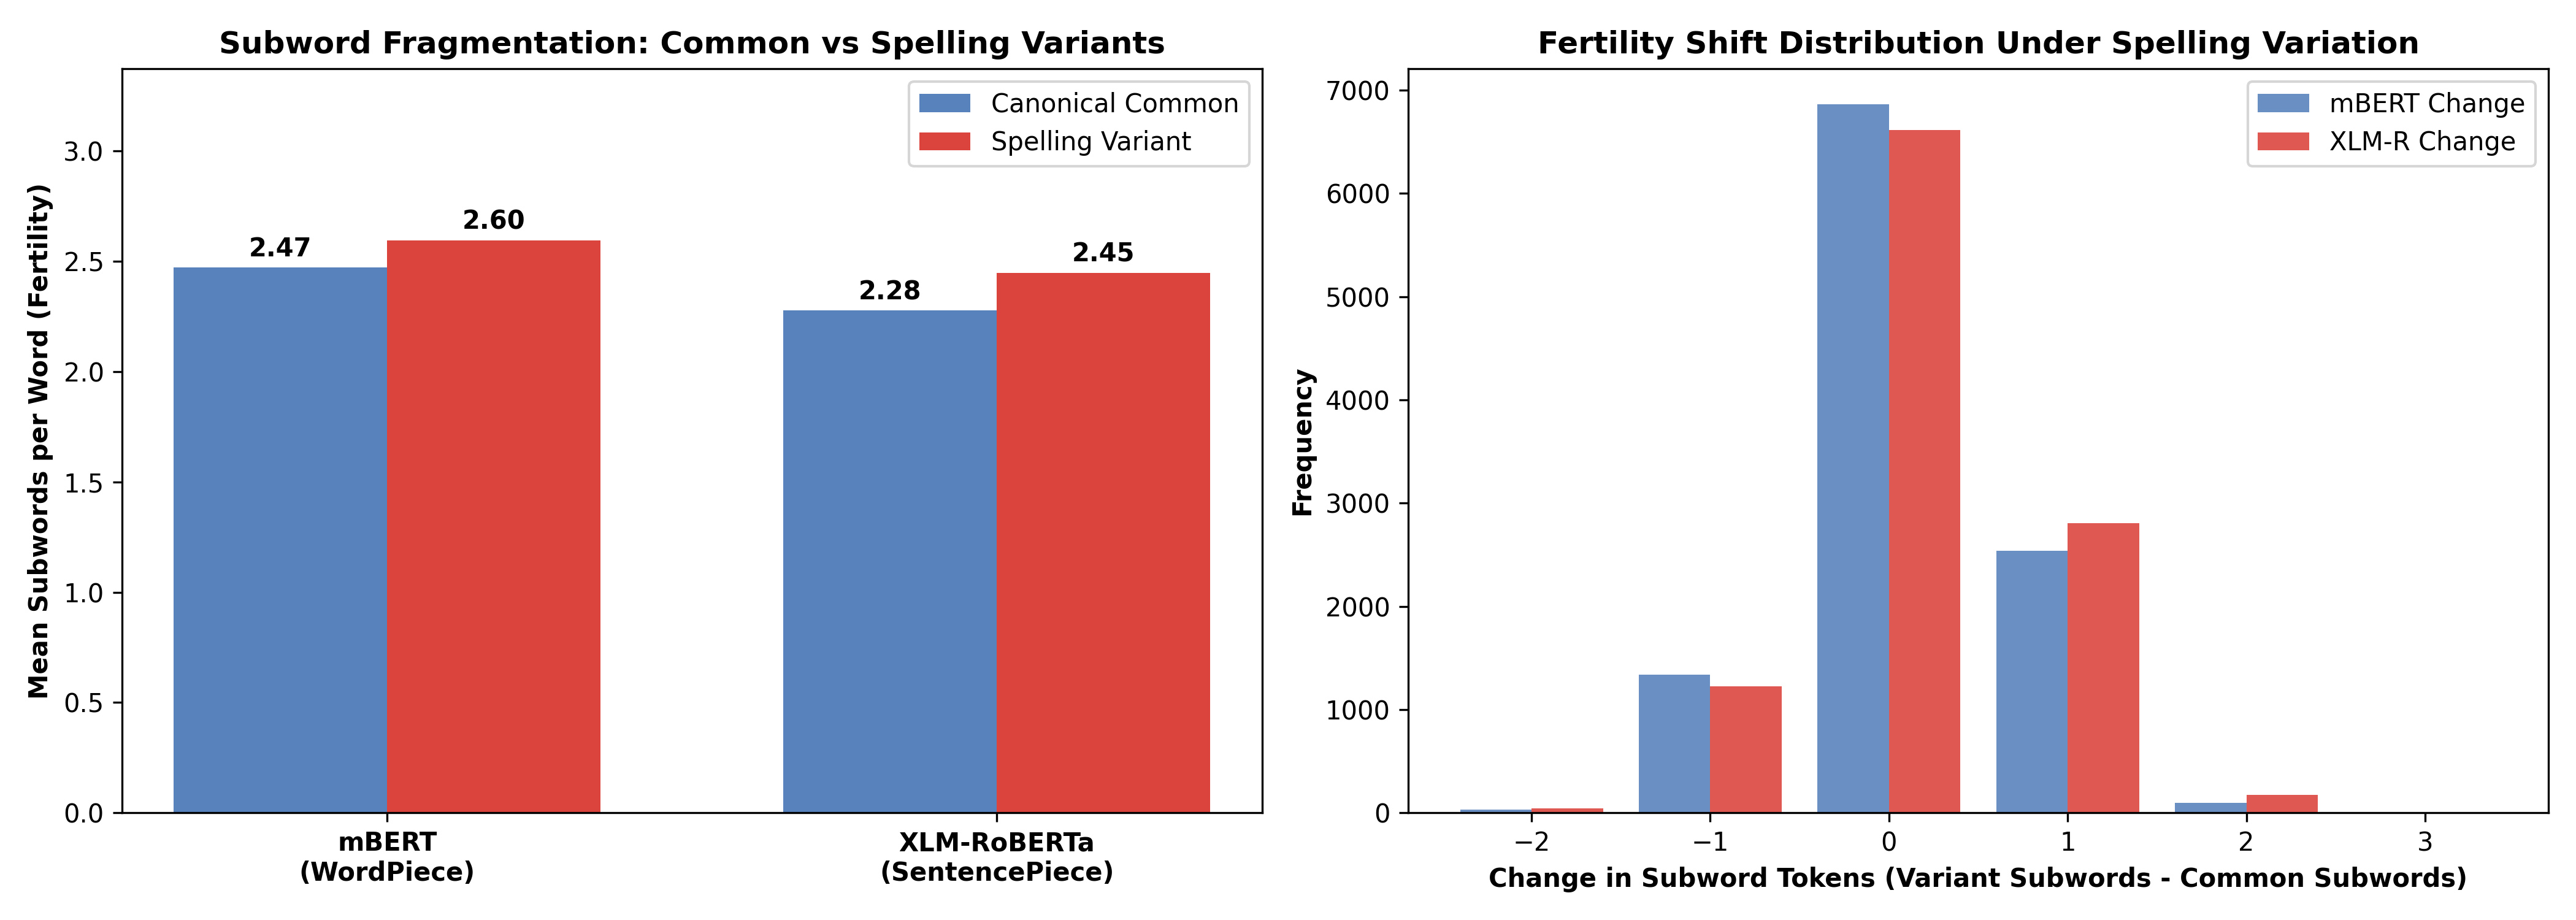

In [6]:
frag_summary_path = os.path.join(PROJECT_ROOT, "results", "tables", "tokenization_fragmentation_summary.json")
with open(frag_summary_path, "r", encoding="utf-8") as f:
    frag_summary = json.load(f)

print("Tokenizer Fragmentation Summary:")
print(json.dumps(frag_summary, indent=2))

display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "tokenizer_fragmentation_comparison.png")))
